In [1]:
%matplotlib widget
import matplotlib.pyplot as plt
import numpy as np

from run_module import run_both

In [2]:
cells_in_parallel = 12
cells_in_series = 6

ecm_parameters = {
    "Initial State of Charge / 1": 0.90,
    "Initial Hysteresis / 1": 1.0,
    "State of Health / 1": np.random.normal(
        1.0, 0.05, (cells_in_series * cells_in_parallel, 1)
    ),
    "State of Resistance / 1": np.random.normal(
        1.0, 0.05, (cells_in_series * cells_in_parallel, 1)
    ),
    "Nominal Capacity / Ah": 5.0,
    "Timeconstant hysteresis / 1": 0.2,
}


module_parameters = {
    "Positive terminal resistance / Ohm": np.random.normal(
        1e-4,
        1e-5,
        cells_in_parallel,
    ).clip(min=1e-9, max=1e-1),
    "Negative terminal resistance / Ohm": np.random.normal(
        1e-4,
        1e-5,
        cells_in_parallel,
    ).clip(min=1e-9, max=1e-1),
    "Series resistance / Ohm": np.random.normal(
        1e-4,
        1e-5,
        (cells_in_series, cells_in_parallel),
    ).clip(min=1e-9, max=1e-1),
    "Parallel resistance / Ohm": np.random.normal(
        1e-3,
        1e-4,
        (cells_in_series + 1, cells_in_parallel - 1),
    ).clip(min=1e-9, max=1e-1),
}

In [3]:
# Create current signal
_c_rate = [np.zeros(300)]
k = int(0.8 * 3600)
for cycle in range(3):
    _c_rate.append(-1 * np.ones(k))
    _c_rate.append(np.zeros(300))
    _c_rate.append(np.ones(k))
_c_rate.append(np.zeros(300))
c_rate = np.hstack(_c_rate)[None, :]
t = np.arange(0, c_rate.size, 1)
print(t[1] - t[0])

1


In [4]:
gitt, ici = run_both(
    time=t,
    c_rate=c_rate,
    cells_in_parallel=cells_in_parallel,
    cells_in_series=cells_in_series,
    ecm_parameters=ecm_parameters,
    module_parameters=module_parameters,
    parallel=True,
)

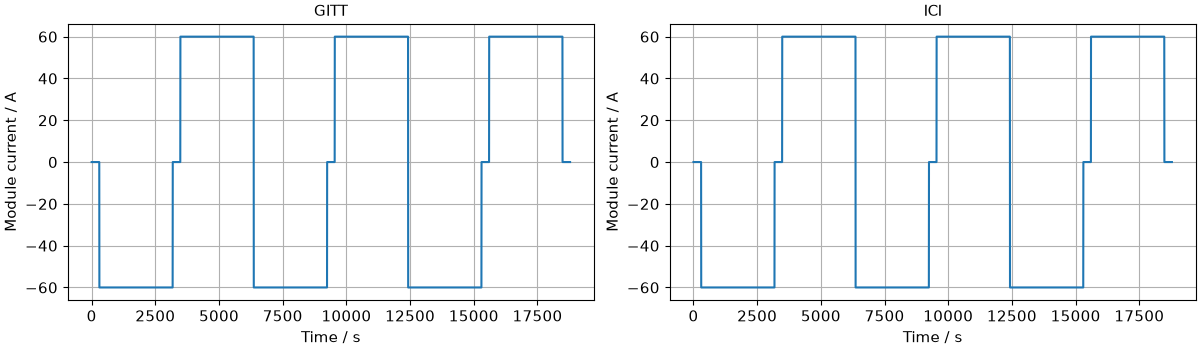

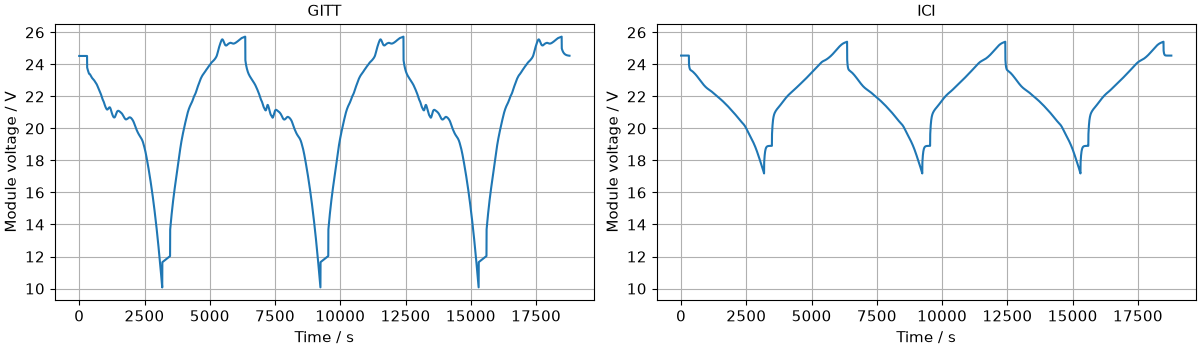

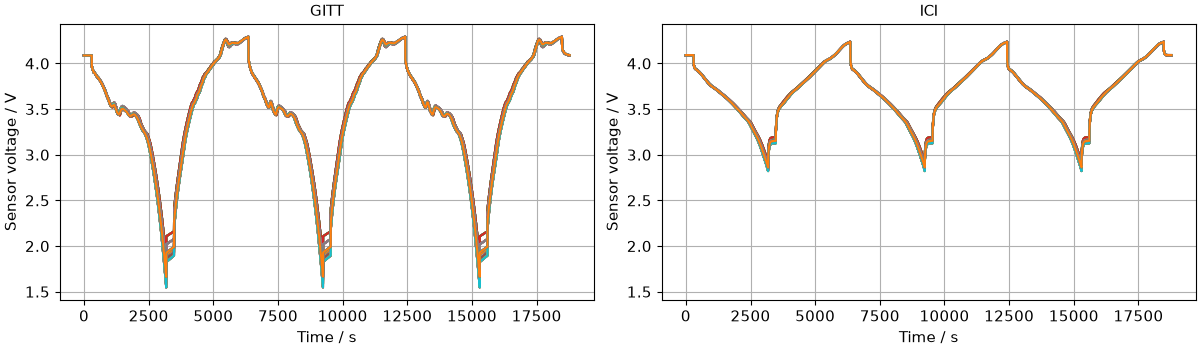

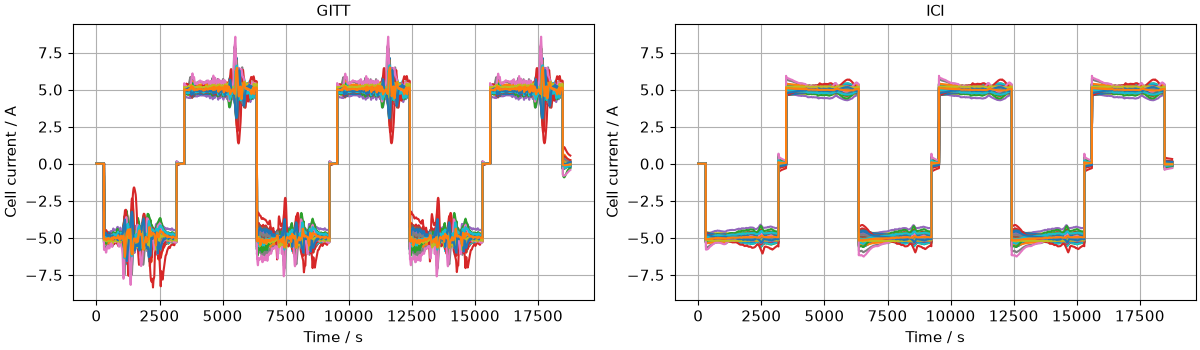

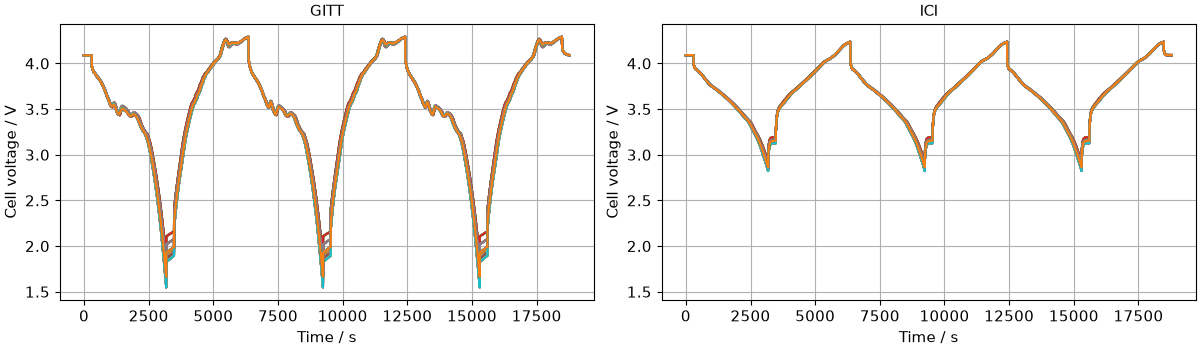

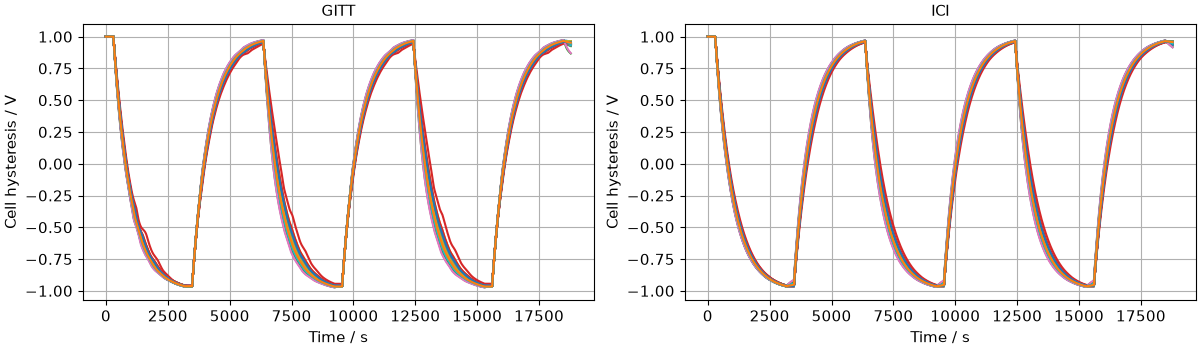

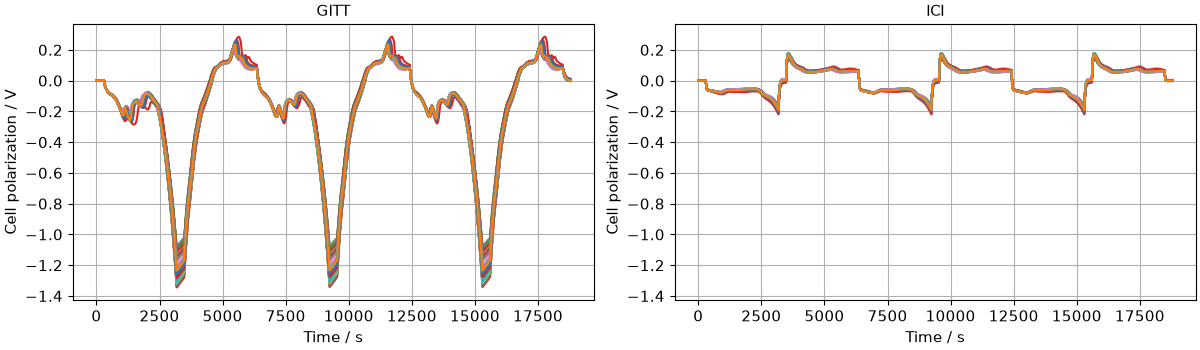

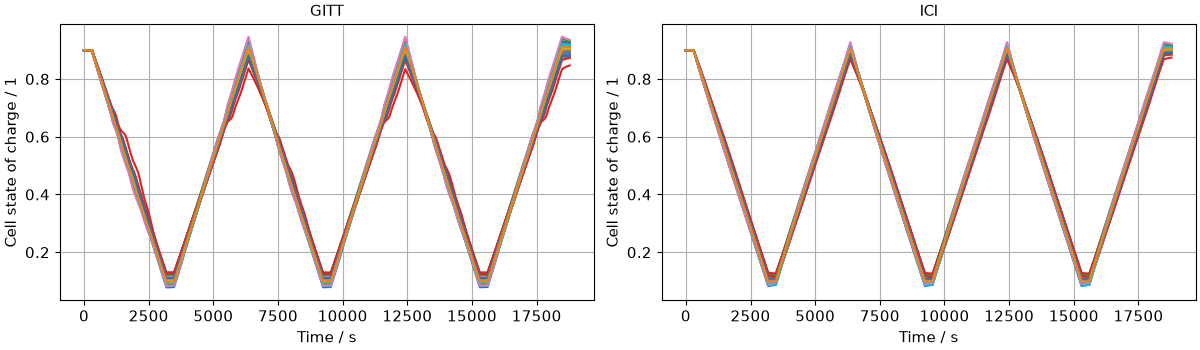

In [6]:
ylabels = {
    "module_current": "Module current / A",
    "module_voltage": "Module voltage / V",
    "sensor_voltage": "Sensor voltage / V",
    "cell_current": "Cell current / A",
    "cell_voltage": "Cell voltage / V",
    "cell_hysteresis": "Cell hysteresis / V",
    "cell_polarization": "Cell polarization / V",
    "cell_soc": "Cell state of charge / 1",
}
for attr in [
    "module_current",
    "module_voltage",
    "sensor_voltage",
    "cell_current",
    "cell_voltage",
    "cell_hysteresis",
    "cell_polarization",
    "cell_soc",
]:
    fig, axs = plt.subplots(
        1, 2, figsize=(12.0, 3.5), sharex=True, sharey=True, constrained_layout=True
    )
    for col, (sol, title) in enumerate([(gitt, "GITT"), (ici, "ICI")]):
        x = t
        y = getattr(sol, attr)
        axs[col].set_xlabel("Time / s", fontsize=11)
        axs[col].plot(x, y.reshape((-1, x.size)).T)
        axs[col].set_ylabel(ylabels[attr], fontsize=11)
        axs[col].set_title(title, fontsize=11)
        axs[col].grid(True)
        axs[col].tick_params(labelbottom=True, labelleft=True, labelsize=11)
    fig.savefig(f"{attr}.png", dpi=300, bbox_inches="tight")
